In [1]:
from datascience import *
import numpy as np

%matplotlib inline
import matplotlib.pyplot as plt
plt.style.use('fivethirtyeight')

In [2]:
births = Table.read_table('data/baby.csv')
births

Birth Weight,Gestational Days,Maternal Age,Maternal Height,Maternal Pregnancy Weight,Maternal Smoker
120,284,27,62,100,False
113,282,33,64,135,False
128,279,28,64,115,True
108,282,23,67,125,True
136,286,25,62,93,False
138,244,33,62,178,False
132,245,23,65,140,False
120,289,25,62,125,False
143,299,30,66,136,True
140,351,27,68,120,False


In [3]:
smoking_and_birth_weight = births.select('Maternal Smoker', 'Birth Weight')
smoking_and_birth_weight

Maternal Smoker,Birth Weight
False,120
False,113
True,128
True,108
False,136
False,138
False,132
False,120
True,143
False,140


In [ ]:
# Crushed ICE:
# 1. get the # of babies born to mothers who smoked & mothers who did not smoke
# 2. get the avg. birth weights of each group

In [5]:
smoking_and_birth_weight.group('Maternal Smoker')

Maternal Smoker,count
False,715
True,459


In [6]:
smoking_and_birth_weight.group('Maternal Smoker', np.average)

Maternal Smoker,Birth Weight average
False,123.085
True,113.819


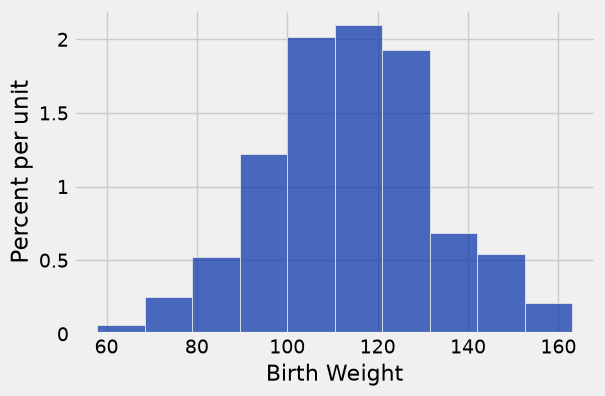

In [8]:
smoking_and_birth_weight.where('Maternal Smoker', True).hist('Birth Weight')

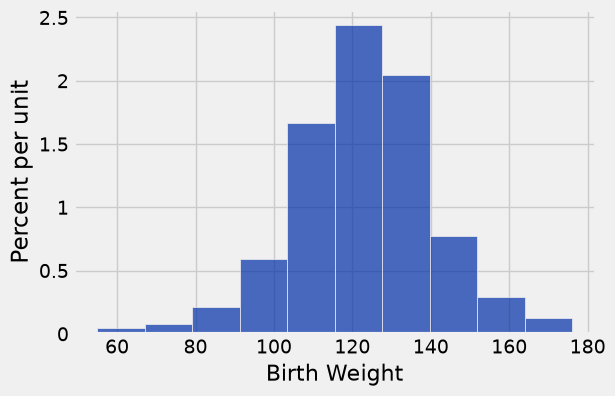

In [9]:
smoking_and_birth_weight.where('Maternal Smoker', False).hist('Birth Weight')

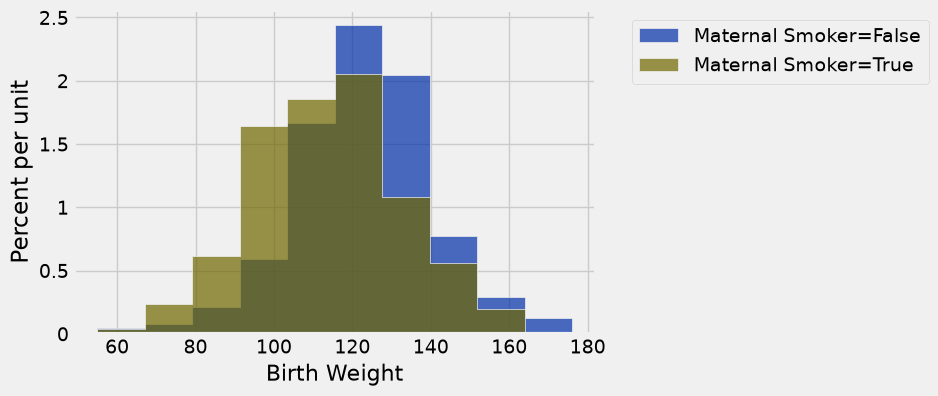

In [10]:
smoking_and_birth_weight.hist('Birth Weight', group='Maternal Smoker')

In [12]:
means_table = smoking_and_birth_weight.group('Maternal Smoker', np.average)
means_table

Maternal Smoker,Birth Weight average
False,123.085
True,113.819


In [13]:
means = means_table.column(1)
observed_difference = means.item(1) - means.item(0)
observed_difference

-9.266142572024918

In [15]:
smoking_and_birth_weight

Maternal Smoker,Birth Weight
False,120
False,113
True,128
True,108
False,136
False,138
False,132
False,120
True,143
False,140


In [16]:
smoking_and_birth_weight.sample(smoking_and_birth_weight.num_rows, with_replacement=False)

Maternal Smoker,Birth Weight
True,101
False,91
True,102
True,99
True,117
False,129
False,127
True,109
False,135
False,128


In [23]:
shuffled_labels = smoking_and_birth_weight.sample(smoking_and_birth_weight.num_rows, with_replacement=False).column(0)
original_and_shuffled = smoking_and_birth_weight.with_column('Shuffled Label', shuffled_labels)
original_and_shuffled

Maternal Smoker,Birth Weight,Shuffled Label
False,120,True
False,113,True
True,128,True
True,108,False
False,136,True
False,138,False
False,132,True
False,120,False
True,143,False
False,140,True


In [27]:
shuffled_only = original_and_shuffled.select('Birth Weight', 'Shuffled Label')
shuffled_group_means = shuffled_only.group('Shuffled Label', np.average)
shuffled_group_means

Shuffled Label,Birth Weight average
False,119.62
True,119.218


In [28]:
means = shuffled_group_means.column(1)
sample_difference = means.item(1) - means.item(0)
sample_difference

-0.4017154958331446

In [29]:
def difference_of_means(table, group_label):
    reduced = table.select('Birth Weight', group_label)
    group_means = reduced.group(group_label, np.average)
    means = group_means.column(1)
    difference = means.item(1) - means.item(0)
    return difference

In [31]:
difference_of_means(original_and_shuffled, 'Maternal Smoker')

-9.266142572024918

In [32]:
difference_of_means(original_and_shuffled, 'Shuffled Label')

-0.4017154958331446

In [33]:
def one_simulated_difference_of_means():
    # make an array of shuffled labels
    shuffled_labels = smoking_and_birth_weight.sample(smoking_and_birth_weight.num_rows, with_replacement=False).column(0)

    # attach to the birth weights of the original table
    original_and_shuffled = smoking_and_birth_weight.with_column('Shuffled Label', shuffled_labels)

    # calculate difference of means using shuffled labels
    return difference_of_means(original_and_shuffled, 'Shuffled Label')

In [39]:
one_simulated_difference_of_means()

-0.20854396148513388

In [40]:
# Crushed ICE: run one_simulated_difference_of_means 5000 times and save each simulated
# difference in an array called differences

In [41]:
differences = make_array()

repetitions = 5000
for i in np.arange(repetitions):
    differences = np.append(differences, one_simulated_difference_of_means())

differences

array([-1.51781769,  0.89682649, -1.39619117, ..., -0.19065771,
       -0.48399226, -0.62350504])

In [42]:
# Crushed ICE: generate a histogram of these differences and compare it to our
# observed_difference
# Generate a p-value too!

Observed Difference: -9.266142572024918


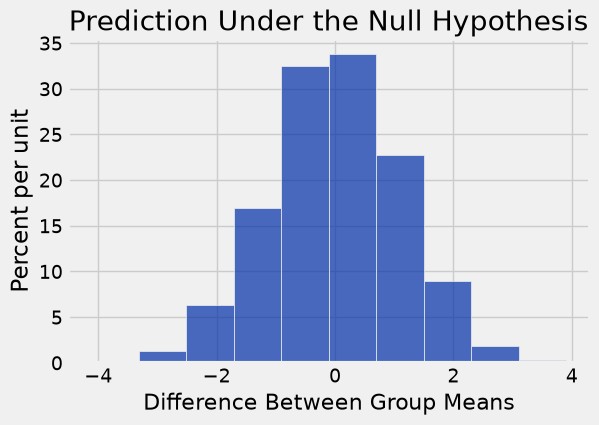

In [43]:
Table().with_column('Difference Between Group Means', differences).hist()
plt.title('Prediction Under the Null Hypothesis')
print('Observed Difference:', observed_difference)

In [44]:
empirical_p = np.count_nonzero(differences <= observed_difference) / repetitions
empirical_p

0.0

In [ ]:
# Conclusion: we reject the null hypothesis

---